# Credit: survival, recovery, migration and structural default

Family 26. Reduced-form default timing and Merton terminal insolvency are
separate models. P default estimation is kept distinct from Q pricing; all
hazards, recoveries and asset values are synthetic.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / 'convexity').exists():
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from convexity.math import contracts as ct, curves as cv, pricing as pr
rng = np.random.default_rng(2600)
ref, expiry = '2026-01-01', '2027-01-01'
discount, dividend = cv.flat_curve(ref, .04), cv.flat_curve(ref, .01)
model = pr.BlackScholesModel(100., discount, dividend, .2)
plt.rcParams.update({'figure.figsize': (9, 3.5), 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .2})
print('Interpreter:', sys.executable)

Interpreter: /home/ethan/miniconda3/envs/quant/bin/python


## Survival and censored default-time simulation

A draw of infinity means survival beyond the requested simulation horizon.
It does not mean the obligor can never default.

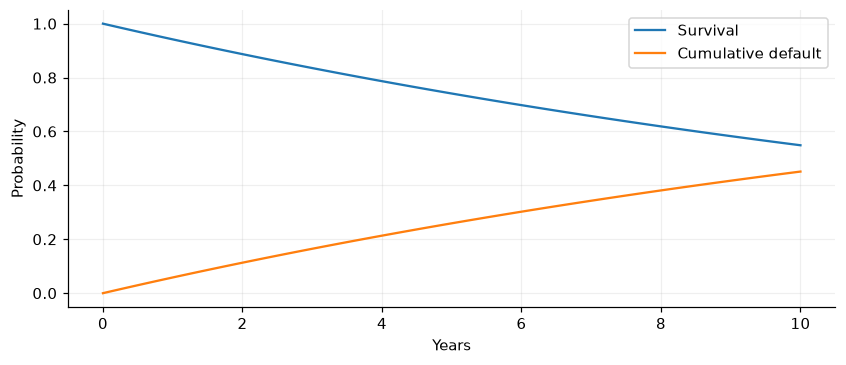

,quantity,value
0,"Default by 5, sampled",0.256400
1,"Default by 5, analytic",0.259182
2,Censored draws,3718.000000


In [2]:
from convexity.math import credit as cr
hazard=cr.flat_hazard(ref,.06)
t=np.linspace(0,10,80)
plt.plot(t,[hazard.survival(T) for T in t],label='Survival')
plt.plot(t,[hazard.default_probability(0,T) for T in t],label='Cumulative default');plt.xlabel('Years');plt.ylabel('Probability');plt.legend();plt.show()
draws=hazard.sample(5000,horizon=5,rng=rng)
display(pd.DataFrame({'quantity':['Default by 5, sampled','Default by 5, analytic','Censored draws'],
 'value':[np.isfinite(draws).mean(),1-np.exp(-.06*5),np.isinf(draws).sum()]}))

## Recovery of par and CDS spread exposure

Risky cash flows include recovery paid at default. The CDS table includes a
current trade date and accrued-premium rebate, so net premium exposure differs
from the coupon leg alone.

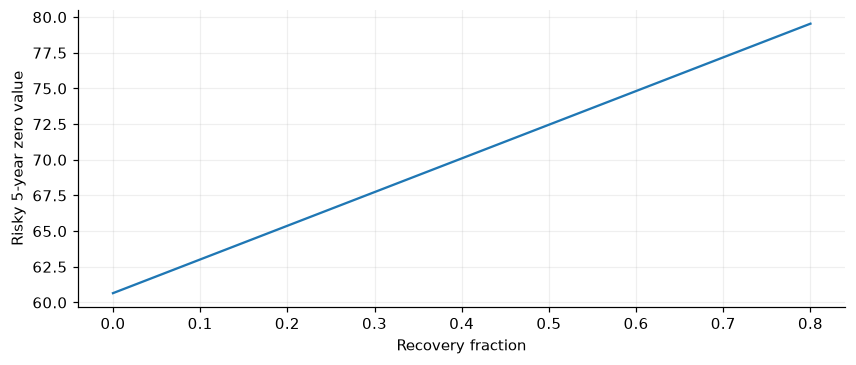

,value,fair_spread,premium_leg,protection_leg,spread_sensitivity,accrual_rebate
0,0.022546,0.035711,-0.118443,0.14099,-3.948116,0.001083


Repriced par CDS NPV: 6.034669292054318e-16


In [3]:
recoveries=np.linspace(0,.8,30)
values=[cr.risky_cashflows([5.],[100.],discount,hazard,recovery=r,recovery_notional=100) for r in recoveries]
plt.plot(recoveries,values);plt.xlabel('Recovery fraction');plt.ylabel('Risky 5-year zero value');plt.show()
dates=ct.schedule('2025-12-20','2030-12-20',months=3)
kwargs=dict(trade_date=ref)
cds=cr.cds_price(dates,.03,discount,hazard,**kwargs)
par=cr.cds_price(dates,cds.fair_spread,discount,hazard,**kwargs)
display(pd.DataFrame([dict(cds.items())]));print('Repriced par CDS NPV:',par.value)

## Rating migration is a full transition law

The final state is absorbing default. The continuous-time generator is
estimated from transition counts and exposure time, not by taking an arbitrary
matrix logarithm of a discrete transition matrix.

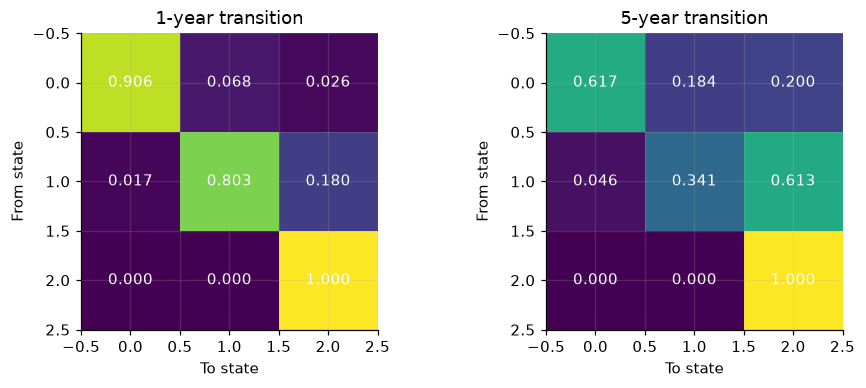

P censored hazard estimate: HazardEstimate(hazard=0.2, events=2, exposure=10.0, standard_error=0.1414213562373095, measure='P')


In [4]:
migration=cr.MigrationModel([[-.10,.08,.02],[.02,-.22,.20],[0.,0.,0.]])
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
for ax,time in zip(axes,[1,5]):
    matrix=migration.transition(time).transition
    ax.imshow(matrix,vmin=0,vmax=1);ax.set(title=f'{time}-year transition',xlabel='To state',ylabel='From state')
    for i in range(3):
        for j in range(3):ax.text(j,i,f'{matrix[i,j]:.3f}',ha='center',va='center',color='white')
plt.show()
print('P censored hazard estimate:',cr.estimate_hazard([2.,3.,5.],[True,False,True]))

## Structural terminal default and the capital structure

Merton values equity as an option on assets and debt as the residual promised
claim with default loss. The direct debt formula avoids numerical cancellation
when asset value is very large. P and Q default probabilities use distinct drifts.

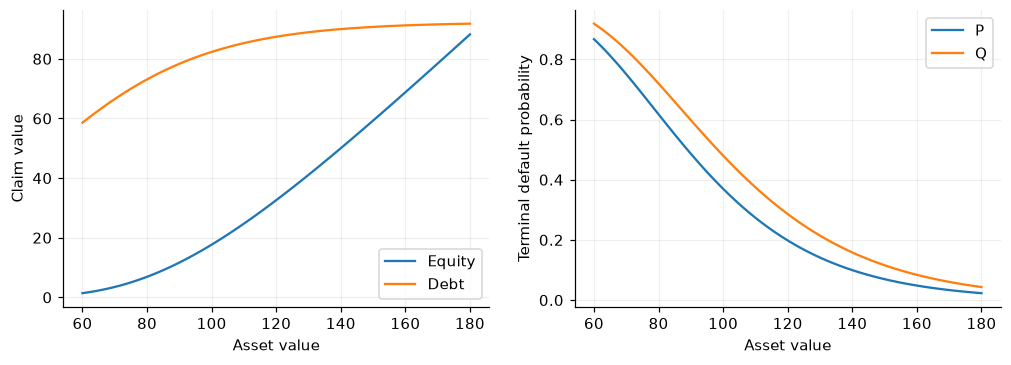

In [5]:
assets=np.linspace(60,180,100)
results=[cr.merton_structural(v,100,.25,2,.04,physical_drift=.09) for v in assets]
fig,axes=plt.subplots(1,2,figsize=(11,3.5))
axes[0].plot(assets,[r.equity for r in results],label='Equity');axes[0].plot(assets,[r.debt for r in results],label='Debt');axes[0].set(xlabel='Asset value',ylabel='Claim value');axes[0].legend()
axes[1].plot(assets,[r.p_default_probability for r in results],label='P');axes[1].plot(assets,[r.q_default_probability for r in results],label='Q');axes[1].set(xlabel='Asset value',ylabel='Terminal default probability');axes[1].legend();plt.show()

## Scope of the evidence

These are generated-data experiments under the stated models, not market forecasts or universal model rankings. Numerical errors, backend restrictions and measure assumptions are documented in the [financial catalog](../docs/financial_mathematics.md) and [QA record](../docs/financial_qa.md). Automated adversarial checks live in `tests/math/finance/`.